# Phase 2B · 05 · Model comparison

**Goal:** put the four tuned models of Phase 2B next to the 2A random forest and the paper, and decide which differences are real. This notebook trains nothing. It only reads the tables the other notebooks saved, so it runs in seconds.

1. Unified AUC per model, with the spread over repeats.
2. LOSO AUC per study for every model.
3. Differences against 2A and the paper, in one summary table.

## Setup

Inputs are the `unified_auc.csv` and `loso_auc.csv` tables of 2A and of notebooks 01 to 04. Quick runs write no tables, so every table read here comes from a full run. Outputs go to `results/figures/phase_2/phase_2b/05_model_comparison/` and `results/tables/phase_2/phase_2b/05_model_comparison/`.

Notebook 2A/01 saved only the median AUC, not the AUC of each repeat. Its repeat range (0.802 to 0.807) is copied from that notebook's printed output.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display


def find_project_root() -> Path:
    """Walk up from the current folder to the one that holds requirements.txt."""
    folder = Path.cwd()
    while not (folder / "requirements.txt").exists():
        if folder.parent == folder:
            raise FileNotFoundError("No requirements.txt above this folder.")
        folder = folder.parent
    return folder


PROJECT_ROOT = find_project_root()
TABLES_2A = PROJECT_ROOT / "results" / "tables" / "phase_2" / "phase_2a"
TABLES_2B = PROJECT_ROOT / "results" / "tables" / "phase_2" / "phase_2b"
FIGURES = PROJECT_ROOT / "results" / "figures" / "phase_2" / "phase_2b" / "05_model_comparison"
TABLES = TABLES_2B / "05_model_comparison"
for folder in (FIGURES, TABLES):
    folder.mkdir(parents=True, exist_ok=True)

MODELS = {"01_tuned_random_forest": "Tuned RF", "02_xgboost": "XGBoost", "03_elastic_net": "Elastic net", "04_svm": "SVM"}
REPEAT_RANGE_2A = (0.802, 0.807)

figure_number = 0


def show_figure(fig: plt.Figure, name: str, caption: str) -> None:
    global figure_number
    figure_number += 1
    fig.savefig(FIGURES / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    display(Markdown(f"**Figure {figure_number}.** {caption}"))

In [2]:
unified_2a = pd.read_csv(TABLES_2A / "01_unified_random_forest" / "unified_auc.csv")
loso_2a = pd.read_csv(TABLES_2A / "02_loso_random_forest" / "loso_auc.csv", index_col="study")
AUC_2A = unified_2a["auc"].iloc[0]
AUC_PAPER = unified_2a["paper_auc"].iloc[0]

unified_rows = [{"model": "2A RF", "auc": AUC_2A, "repeat_min": REPEAT_RANGE_2A[0], "repeat_max": REPEAT_RANGE_2A[1]}]
loso = pd.DataFrame({"Paper": loso_2a["paper_auc"], "2A RF": loso_2a["our_auc"]})
for folder, name in MODELS.items():
    table = pd.read_csv(TABLES_2B / folder / "unified_auc.csv").iloc[0]
    unified_rows.append({"model": name, "auc": table["auc_median"],
                         "repeat_min": table["auc_repeat_min"], "repeat_max": table["auc_repeat_max"]})
    loso[name] = pd.read_csv(TABLES_2B / folder / "loso_auc.csv", index_col="study")["auc"]
unified = pd.DataFrame(unified_rows).set_index("model")
in_paper = loso["Paper"].notna()
print(f"{len(unified)} models, {len(loso)} LOSO studies ({in_paper.sum()} with a paper value)")
unified

5 models, 27 LOSO studies (26 with a paper value)


,auc,repeat_min,repeat_max
model,,,
2A RF,0.8085,0.8020,0.8070
Tuned RF,0.8079,0.8027,0.8085
XGBoost,0.8186,0.8001,0.8184
Elastic net,0.7952,0.7920,0.8057
SVM,0.8052,0.7950,0.8078


## 1. Unified AUC

Each model's AUC comes from the median over 10 repeats. Running the same model with other random fold splits moves the AUC of a single repeat, and the min-to-max range of the repeats shows how much. For 2A that range is 0.005 wide.

**Our rule:** a model counts as better or worse than 2A only if its AUC differs from 2A's by more than 2A's repeat spread. A smaller difference could come from the fold split alone, so it is called no real difference.

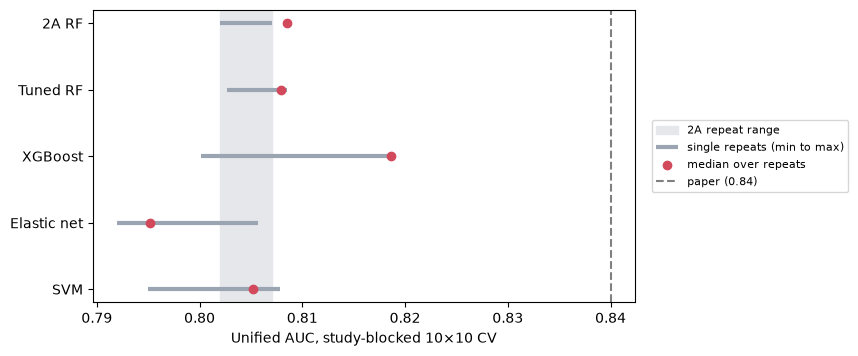

**Figure 1.** Unified AUC per model. The bar spans the 10 single repeats, the dot is the AUC of the median over repeats, and the grey band is 2A's repeat range. A model differs from 2A (0.808) only if the gap is larger than 0.005: Tuned RF 0.808 (no real difference), XGBoost 0.819 (better), Elastic net 0.795 (worse), SVM 0.805 (no real difference). The paper reports 0.84.

In [3]:
spread_2a = REPEAT_RANGE_2A[1] - REPEAT_RANGE_2A[0]
difference_2a = unified["auc"] - AUC_2A
unified["vs_2a"] = np.where(difference_2a.abs() <= spread_2a, "no real difference",
                            np.where(difference_2a > 0, "better", "worse"))
unified.loc["2A RF", "vs_2a"] = "reference"

fig, ax = plt.subplots(figsize=(7, 3.8))
positions = np.arange(len(unified))[::-1]
ax.axvspan(*REPEAT_RANGE_2A, color="#E5E7EB", label="2A repeat range")
ax.hlines(positions, unified["repeat_min"], unified["repeat_max"], color="#9AA5B1", linewidth=3, label="single repeats (min to max)")
ax.scatter(unified["auc"], positions, color="#D1495B", zorder=3, label="median over repeats")
ax.axvline(AUC_PAPER, color="grey", linestyle="--", label=f"paper ({AUC_PAPER})")
ax.set_yticks(positions, unified.index)
ax.set_xlabel("Unified AUC, study-blocked 10×10 CV")
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=8)

show_figure(
    fig,
    "unified_by_model",
    f"Unified AUC per model. The bar spans the 10 single repeats, the dot is the AUC of the median over repeats, and the "
    f"grey band is 2A's repeat range. A model differs from 2A ({AUC_2A:.3f}) only if the gap is larger than "
    f"{spread_2a:.3f}: "
    + ", ".join(f"{name} {row.auc:.3f} ({row.vs_2a})" for name, row in unified.drop(index="2A RF").iterrows())
    + f". The paper reports {AUC_PAPER}.",
)

## 2. LOSO per study

Each row is one held-out study, sorted by the 2A forest's AUC. Each dot is one model trained on the other 26 studies. The means in the legend are over the 26 studies that have a value in the paper's Table S5.

LOSO trains one model per study, with no repeats, so there is no spread to compare against. The question here is whether a model is better on most studies or only on a few.

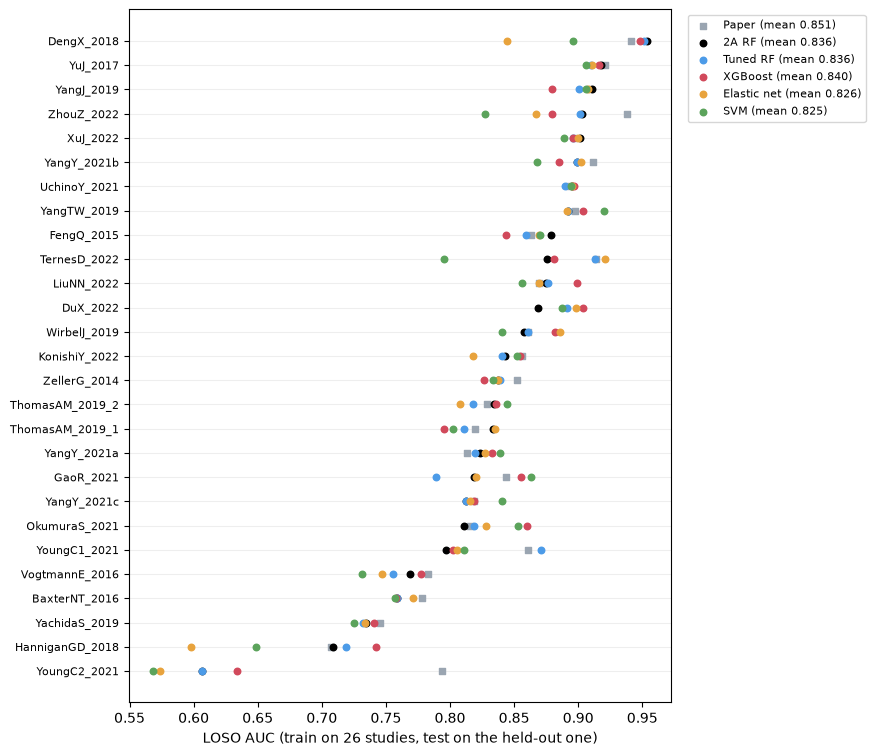

**Figure 2.** LOSO AUC of every model for each of the 27 held-out studies (DuX_2022 has no paper value). Within one study the five models differ by 0.046 on average (best minus worst), while the studies' mean AUCs range from 0.598 (YoungC2_2021) to 0.919 (DengX_2018). Which study is held out matters far more than which model is used.

In [4]:
model_names = ["2A RF", *MODELS.values()]
colors = {"Paper": "#9AA5B1", "2A RF": "black", "Tuned RF": "#4C9BE8", "XGBoost": "#D1495B",
          "Elastic net": "#E8A33D", "SVM": "#5BA35B"}
order = loso["2A RF"].sort_values().index

fig, ax = plt.subplots(figsize=(7, 9))
positions = np.arange(len(order))
for name, color in colors.items():
    ax.scatter(loso.loc[order, name], positions, color=color, marker="s" if name == "Paper" else "o", s=22,
               label=f"{name} (mean {loso.loc[in_paper, name].mean():.3f})", zorder=2 if name == "Paper" else 3)
ax.set_yticks(positions, order, fontsize=8)
ax.grid(axis="y", color="#EEEEEE")
ax.set_xlabel("LOSO AUC (train on 26 studies, test on the held-out one)")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=8)

model_range = loso[model_names].max(axis=1) - loso[model_names].min(axis=1)
study_mean = loso[model_names].mean(axis=1)
show_figure(
    fig,
    "loso_by_model",
    f"LOSO AUC of every model for each of the {len(loso)} held-out studies ({', '.join(loso.index[~in_paper])} has no "
    f"paper value). Within one study the five models differ by {model_range.mean():.3f} on average (best minus worst), "
    f"while the studies' mean AUCs range from {study_mean.min():.3f} ({study_mean.idxmin()}) to "
    f"{study_mean.max():.3f} ({study_mean.idxmax()}). Which study is held out matters far more than which model is used.",
)

## 3. Summary

One row per model, measured the same way as in 2A:

- `unified_auc`, `repeat_min`, `repeat_max`: the unified evaluation from section 1, with the verdict against 2A.
- `loso_mean`: mean LOSO AUC over the 26 studies in Table S5.
- `loso_mad_vs_paper`: mean absolute difference from the paper's per-study AUCs (lower is closer to the paper).
- `within_005_of_paper`: how many of the 26 studies are within ±0.05 of the paper.
- `loso_mean_diff_vs_2a`: `loso_mean` minus the 2A forest's.
- `loso_better_than_2a`: in how many of the 27 studies the model beats the 2A forest.

In [5]:
on_paper_studies = loso.loc[in_paper, model_names]
vs_paper = on_paper_studies.sub(loso.loc[in_paper, "Paper"], axis=0)

summary = unified.rename(columns={"auc": "unified_auc", "vs_2a": "unified_vs_2a"})
summary["loso_mean"] = on_paper_studies.mean()
summary["loso_mad_vs_paper"] = vs_paper.abs().mean()
summary["within_005_of_paper"] = (vs_paper.abs() <= 0.05).sum()
summary["loso_mean_diff_vs_2a"] = summary["loso_mean"] - summary.loc["2A RF", "loso_mean"]
summary["loso_better_than_2a"] = (loso[model_names].sub(loso["2A RF"], axis=0) > 0).sum()
paper_row = pd.DataFrame({"unified_auc": [AUC_PAPER], "loso_mean": [loso.loc[in_paper, "Paper"].mean()]}, index=["Paper"])
summary = pd.concat([paper_row, summary])[summary.columns].rename_axis("model")
count_columns = ["within_005_of_paper", "loso_better_than_2a"]
summary[count_columns] = summary[count_columns].astype("Int64")
summary.round(4).to_csv(TABLES / "model_summary.csv")
summary.round(3)

,unified_auc,repeat_min,repeat_max,unified_vs_2a,loso_mean,loso_mad_vs_paper,within_005_of_paper,loso_mean_diff_vs_2a,loso_better_than_2a
model,,,,,,,,,
Paper,0.840,NaN,NaN,NaN,0.851,NaN,<NA>,NaN,<NA>
2A RF,0.808,0.802,0.807,reference,0.836,0.021,24,0.000,0
Tuned RF,0.808,0.803,0.808,no real difference,0.836,0.019,24,-0.000,8
XGBoost,0.819,0.800,0.818,better,0.840,0.025,23,0.004,17
Elastic net,0.795,0.792,0.806,worse,0.826,0.032,21,-0.010,12
SVM,0.805,0.795,0.808,no real difference,0.825,0.038,20,-0.012,9


## 4. Checks

In [6]:
assert len(summary) == 6, "paper, 2A and the four 2B models"
assert not summary.drop(index="Paper").isna().any().any()
assert len(loso) == 27 and not loso[model_names].isna().any().any()
assert in_paper.sum() == 26
for folder in MODELS:
    assert (TABLES_2B / folder / "unified_auc.csv").exists()
    assert len(pd.read_csv(TABLES_2B / folder / "chosen_params.csv")) == 127, "100 unified splits + 27 LOSO, so a full run"
print("All checks passed.")

All checks passed.
